# Vergleich mit Analysten

In [1]:
import sys
import os
import dotenv

# Get the current directory
current_dir = os.getcwd()

# Go up one level to the parent directory
parent_dir = os.path.dirname(current_dir)

# Add the parent directory to the Python path
sys.path.append(parent_dir)

In [2]:
from portfolio_ai import PortfolioAIAssistant

In [ ]:
assistant = PortfolioAIAssistant(
    provider="ollama",
    model="qwen3:30b",
    finance_provider="yfinance",
    ensemble=False,
)

pf = assistant.new_portfolio("Sample Portfolio", "Long-term growth / balanced risk")
pf.add_asset("MBGAF", name="Mercedes-Benz Group")
#pf.add_trade("MBG.DE", quantity=10, price=50.10, date_str="2023-05-01")
#pf.add_trade("MBG.DE", quantity=56, price=52.00, date_str="2023-06-01")

pf.add_asset("GOOG", name="Alphabet")
#pf.add_trade("GOOG", quantity=25, price=134.50, date_str="2023-02-15")

pf.add_asset("ASML", name="ASML Holding N.V.")

pf.add_asset("DKILY", name="Daikin Industries")
#pf.add_asset("EUNL", name="iShares Core MSCI World UCITS ETF USD (Acc)")

In [4]:
from datetime import datetime

result_saves_dict = {}

In [5]:
for i in range(1): # wieder auf 10 ändern

    print("Running iteration", i)

    current_timestamp = datetime.now().isoformat(timespec='seconds')

    result = assistant.evaluate_portfolio(pf)

    result_saves_dict[current_timestamp] = result

Running iteration 0
Evaluating MBG.DE ...
Getting quantitative data for MBG.DE took 11.20s
Getting LLM asset analysis for MBG.DE took 206.94s
The LLM evaluation for MBG.DE took 22.37s
Evaluating GOOG ...
Getting quantitative data for GOOG took 0.61s
Getting LLM asset analysis for GOOG took 75.55s
The LLM evaluation for GOOG took 15.80s
Evaluating ASML ...
Getting quantitative data for ASML took 0.58s
Getting LLM asset analysis for ASML took 110.78s
The LLM evaluation for ASML took 19.23s
Evaluating DKI.F ...
Getting quantitative data for DKI.F took 0.66s
Getting LLM asset analysis for DKI.F took 69.24s
The LLM evaluation for DKI.F took 13.67s
Evaluating portfolio ...


In [6]:
# just temporary
result_saves_dict_backup = result_saves_dict

In [7]:


print(result_saves_dict)

{'2025-08-27T18:42:42': {'portfolio_name': 'Sample Portfolio', 'investor_goals': 'Long-term growth / balanced risk', 'assets': {'MBG.DE': {'name': 'Mercedes-Benz Group', 'trades': [], 'evaluation_results': {'urgency': 75, 'buy': 40, 'sell': 10, 'hold': 50, 'potential_upside': 0, 'potential_downside': 0, 'explanation_evaluation': 'Munich Re (MUV2) shows strong fundamentals with 10% YoY profit growth and strategic AI investments. Climate risk exposure is a key risk, but opportunities in climate tech and cyber insurance outweigh it. Current price (€53.27) reflects solid valuation (PE 7.5x), suggesting upside potential. Hold for stability, with buy signals for long-term growth.', 'prompts': {'llm_brief_prompt': 'Give a concise business overview, recent events, and key risks/opportunities for MBG.DE.', 'assessment_messages': [{'role': 'system', 'content': 'You are a disciplined equity analyst. Return strictly the requested JSON schema. Numbers are integers [0..100].'}, {'role': 'human', 'co

In [8]:
def print_dict_tree(d, indent=0, hide_values=False, max_depth=None, current_depth=0, only_show_the_following_keys=None):
    if max_depth is not None and current_depth >= max_depth:
        return  # Stop recursion if the maximum depth is reached

    if only_show_the_following_keys is None:
        only_show_the_following_keys = []  # Initialize to an empty list if None

    for key, value in d.items():
        print(' ' * indent + str(key))  # Print the key with indentation

        # Check if the current key is in the list of keys to show
        if isinstance(value, dict):  # If the value is a dictionary, recurse
            print_dict_tree(value, indent + 4, hide_values, max_depth, current_depth + 1, only_show_the_following_keys)
        elif not hide_values or key in only_show_the_following_keys:  # Print the value if hide_values is False or key is in the list
            print(' ' * (indent + 4) + str(value))  # Print the value with indentation

In [9]:
print_dict_tree(result_saves_dict, only_show_the_following_keys=["urgency", "buy", "sell", "hold", "potential_upside", "potential_downside"], hide_values=True)

# Additional options:
# Only certain keys

2025-08-27T18:42:42
    portfolio_name
    investor_goals
    assets
        MBG.DE
            name
            trades
            evaluation_results
                urgency
                    75
                buy
                    40
                sell
                    10
                hold
                    50
                potential_upside
                    0
                potential_downside
                    0
                explanation_evaluation
                prompts
                    llm_brief_prompt
                    assessment_messages
                last_evaluated_at
        GOOG
            name
            trades
            evaluation_results
                urgency
                    75
                buy
                    40
                sell
                    15
                hold
                    45
                potential_upside
                    0
                potential_downside
                    0
               

In [10]:
print(result["assets"]["MBG.DE"]["evaluation_results"])

{'urgency': 75, 'buy': 40, 'sell': 10, 'hold': 50, 'potential_upside': 0, 'potential_downside': 0, 'explanation_evaluation': 'Munich Re (MUV2) shows strong fundamentals with 10% YoY profit growth and strategic AI investments. Climate risk exposure is a key risk, but opportunities in climate tech and cyber insurance outweigh it. Current price (€53.27) reflects solid valuation (PE 7.5x), suggesting upside potential. Hold for stability, with buy signals for long-term growth.', 'prompts': {'llm_brief_prompt': 'Give a concise business overview, recent events, and key risks/opportunities for MBG.DE.', 'assessment_messages': [{'role': 'system', 'content': 'You are a disciplined equity analyst. Return strictly the requested JSON schema. Numbers are integers [0..100].'}, {'role': 'human', 'content': 'You may receive any subset of the following sections. If a section is missing or empty, treat it as \'unknown\'.\n\nTicker: MBG.DE\n\nQuantitative data (JSON, may be partial):\n{\n  "current_price"

In [11]:
from collections import defaultdict, Counter
from typing import Dict, Any, List, Union, Optional, Tuple, Set
import math

Number = Union[int, float]

# ------------------------- helpers (unchanged) -------------------------

def _safe_number(x: Any) -> Optional[float]:
    """Return float(x) if x is a finite number, otherwise None."""
    if isinstance(x, (int, float)) and math.isfinite(x):
        return float(x)
    return None

def _mean(values: List[float]) -> float:
    """Arithmetic mean; assumes values is non-empty."""
    return sum(values) / len(values)

def _mean_abs_dev(values: List[float], mean_value: float) -> float:
    """Mean absolute deviation from the mean (in the same units as values)."""
    return sum(abs(v - mean_value) for v in values) / len(values)

def _mean_rel_dev(values: List[float], mean_value: float) -> Optional[float]:
    """
    Mean absolute relative deviation: mean(|v - mean|) / |mean|.
    Returns None if mean is (near) zero and no sensible relative baseline exists.
    """
    denom = abs(mean_value)
    if denom < 1e-12:
        # If all values are ~0, relative deviation is undefined -> None
        if all(abs(v) < 1e-12 for v in values):
            return None
        # Else fall back to mean absolute value as a softer baseline
        denom = sum(abs(v) for v in values) / len(values)
        if denom < 1e-12:
            return None
    return _mean_abs_dev(values, mean_value) / denom

def _max_abs_dev(values: List[float], mean_value: float) -> float:
    """Maximum absolute deviation from the mean."""
    return max(abs(v - mean_value) for v in values)

def _identical_count(values: List[float], rounding_decimals: int = 4) -> int:
    """
    Count of the most frequent (i.e., largest group of) identical values.
    Uses rounding to make equality robust to tiny float noise.
    """
    rounded = [round(v, rounding_decimals) for v in values]
    freq = Counter(rounded)
    return max(freq.values()) if freq else 0

# ------------------------- asset utilities -------------------------

def _extract_asset_display_and_aliases(asset_key: Optional[str], asset: Dict[str, Any]) -> Tuple[str, Set[str]]:
    """
    Determine a human-friendly display name for the asset and a set of aliases
    that can be used for filtering (e.g., ticker, symbol, provided key, etc.).
    """
    # Common fields we might find in various data structures
    candidates = [
        asset.get("name"),
        asset.get("display_name"),
        asset.get("longName"),
        asset.get("shortName"),
        asset.get("symbol"),
        asset.get("ticker"),
        asset.get("id"),
        asset.get("isin"),
        asset_key,
    ]
    # Choose first non-empty string as display name
    display = next((str(c) for c in candidates if isinstance(c, str) and c.strip()), "Unknown Asset")
    # Build alias set for filtering (case-insensitive)
    aliases = {str(c).strip().lower() for c in candidates if isinstance(c, str) and c.strip()}
    return display, aliases

# ------------------------- main function (UPDATED) -------------------------

def aggregate_evaluation_stats(
    result_saves_dict: Dict[str, Any],
    specific_assets: Optional[List[str]] = None,
) -> Dict[str, Dict[str, Dict[str, Any]]]:
    """
    Aggregate evaluation statistics PER ASSET across all timestamps.

    Changes vs your previous version:
      1) The returned dictionary is now keyed first by the **asset name**, then by metric:
           {
             "Asset A": { "urgency": {...}, "buy": {...}, ... },
             "Asset B": { ... }
           }
      2) 'specific_assets' is now a LIST. When provided, only assets whose name/ticker/etc
         matches any element (case-insensitive) are included.

    The metrics computed for each asset/metric are:
      - mean                         (in %)
      - avg_abs_dev_pp              (mean absolute deviation in percentage points)
      - avg_rel_dev_pct             (mean absolute relative deviation, in % of mean)
      - identical_values_count      (max frequency of identical values; rounded to 4dp)
      - max_abs_dev_pp              (max absolute deviation from mean, in percentage points)
      - count, unique_values
      - orig_values_list            (all raw values collected)

    Expected structure in `result_saves_dict`:
      result_saves_dict[timestamp]["assets"] may be either:
        • a dict: { "<asset_key>": { "evaluation_results": {...}, ... }, ... }
        • a list: [ { "name": "...", "evaluation_results": {...}, ... }, ... ]
    """
    METRICS = [
        "urgency",
        "buy",
        "sell",
        "hold",
        "potential_upside",
        "potential_downside",
    ]

    # Normalize asset filter to a lowercase set of search terms
    filter_set: Optional[Set[str]] = None
    if specific_assets:
        filter_set = {str(x).strip().lower() for x in specific_assets if isinstance(x, str) and x.strip()}

    # collected[asset_display][metric] -> list of values across timestamps
    collected: Dict[str, Dict[str, List[float]]] = defaultdict(lambda: defaultdict(list))

    # -------- traverse all timestamps and assets --------
    for _ts, payload in (result_saves_dict or {}).items():
        assets = (payload or {}).get("assets", {})

        # Case 1: dict of assets
        if isinstance(assets, dict):
            iterable = list(assets.items())
        # Case 2: list of assets
        elif isinstance(assets, list):
            iterable = [(None, a) for a in assets]  # asset_key unknown
        else:
            continue

        for asset_key, asset in iterable:
            if not isinstance(asset, dict):
                continue

            #display_name, aliases = _extract_asset_display_and_aliases(asset_key, asset)
            display_name = asset_key

            # Apply filter if provided
            if filter_set is not None and aliases.isdisjoint(filter_set):
                continue

            eval_res = asset.get("evaluation_results", {})
            if not isinstance(eval_res, dict):
                continue

            for m in METRICS:
                val = _safe_number(eval_res.get(m))
                if val is not None:
                    collected[display_name][m].append(val)

    # -------- compute stats per asset & metric --------
    def _empty_stats():
        return {
            "count": 0,
            "mean": None,
            "avg_abs_dev_pp": None,
            "avg_rel_dev_pct": None,
            "identical_values_count": 0,
            "max_abs_dev_pp": None,
            "unique_values": 0,
            "orig_values_list": [],
        }

    result: Dict[str, Dict[str, Dict[str, Any]]] = {}

    for asset_name, metric_dict in collected.items():
        asset_stats: Dict[str, Dict[str, Any]] = {}

        for m in METRICS:
            values = metric_dict.get(m, [])
            if not values:
                asset_stats[m] = _empty_stats()
                continue

            mu = _mean(values)
            mad = _mean_abs_dev(values, mu)
            mrd = _mean_rel_dev(values, mu)  # fraction
            max_dev = _max_abs_dev(values, mu)
            ident_ct = _identical_count(values, rounding_decimals=4)

            asset_stats[m] = {
                "count": len(values),
                "mean": mu,
                "avg_abs_dev_pp": mad,
                "avg_rel_dev_pct": (mrd * 100.0) if mrd is not None else None,
                "identical_values_count": ident_ct,
                "max_abs_dev_pp": max_dev,
                "unique_values": len(set(round(v, 4) for v in values)),
                "orig_values_list": list(values),
            }

        # Ensure all metrics exist even if missing
        for m in METRICS:
            asset_stats.setdefault(m, _empty_stats())

        result[asset_name] = asset_stats

    return result

# ------------------------- example usage -------------------------
# stats_by_asset = aggregate_evaluation_stats(result_saves_dict, specific_assets=["Mercedes-Benz Group", "MBG.DE"])
# print(stats_by_asset["Mercedes-Benz Group"]["buy"])


In [12]:
stats_summary = aggregate_evaluation_stats(result_saves_dict)
print(stats_summary)

{'MBG.DE': {'urgency': {'count': 1, 'mean': 75.0, 'avg_abs_dev_pp': 0.0, 'avg_rel_dev_pct': 0.0, 'identical_values_count': 1, 'max_abs_dev_pp': 0.0, 'unique_values': 1, 'orig_values_list': [75.0]}, 'buy': {'count': 1, 'mean': 40.0, 'avg_abs_dev_pp': 0.0, 'avg_rel_dev_pct': 0.0, 'identical_values_count': 1, 'max_abs_dev_pp': 0.0, 'unique_values': 1, 'orig_values_list': [40.0]}, 'sell': {'count': 1, 'mean': 10.0, 'avg_abs_dev_pp': 0.0, 'avg_rel_dev_pct': 0.0, 'identical_values_count': 1, 'max_abs_dev_pp': 0.0, 'unique_values': 1, 'orig_values_list': [10.0]}, 'hold': {'count': 1, 'mean': 50.0, 'avg_abs_dev_pp': 0.0, 'avg_rel_dev_pct': 0.0, 'identical_values_count': 1, 'max_abs_dev_pp': 0.0, 'unique_values': 1, 'orig_values_list': [50.0]}, 'potential_upside': {'count': 1, 'mean': 0.0, 'avg_abs_dev_pp': 0.0, 'avg_rel_dev_pct': None, 'identical_values_count': 1, 'max_abs_dev_pp': 0.0, 'unique_values': 1, 'orig_values_list': [0.0]}, 'potential_downside': {'count': 1, 'mean': 0.0, 'avg_abs_dev

In [13]:
### Bis hierhin identisch mit Konsistenz-Notebook

In [ ]:
# ====================== Analyst comparison (builds ON TOP of your code) ======================
# Uses `result_saves_dict` and `stats_summary` produced by your existing script.
# Compares LLM means (buy/hold/sell) to analyst recommendation trends from Finnhub via MAPE.
# --------------------------------------------------------------------------------------------

from typing import Dict, Any, Optional, Tuple, List
import math
import os
import dotenv
import finnhub

# --- Load API key (expects FINNHUB_API_KEY in your environment/.env) ---
dotenv.load_dotenv()
_FINNHUB_API_KEY = os.getenv("FINNHUB_API_KEY", "")

# --- Finnhub client and helpers (kept separate to not modify your code) ---
def _finnhub_client(api_key: str) -> Optional[finnhub.Client]:
    if not api_key:
        return None
    try:
        return finnhub.Client(api_key=api_key)
    except Exception:
        return None

def _get_finnhub_recommendations(symbol: str, client: Optional[finnhub.Client]) -> List[Dict[str, Any]]:
    """Fetch recommendation trends for a symbol (list of monthly snapshots)."""
    if client is None or not symbol:
        return []
    try:
        return client.recommendation_trends(symbol)
    except Exception:
        return []

def _latest_recommendation_to_percentages(recs: List[Dict[str, Any]]) -> Tuple[Optional[Dict[str, float]], Optional[str]]:
    """
    Convert the latest Finnhub recommendation record to buy/hold/sell percentages.
    strongBuy is merged into buy; strongSell into sell.
    """
    if not recs:
        return None, None
    latest = max(recs, key=lambda r: str(r.get("period", "")))
    b  = float(latest.get("buy", 0.0) or 0.0)
    hb = float(latest.get("strongBuy", 0.0) or 0.0)
    h  = float(latest.get("hold", 0.0) or 0.0)
    s  = float(latest.get("sell", 0.0) or 0.0)
    hs = float(latest.get("strongSell", 0.0) or 0.0)
    total = b + hb + h + s + hs
    if total <= 0:
        return None, latest.get("period")
    return {
        "buy":  (b + hb) / total * 100.0,
        "hold": h / total * 100.0,
        "sell": (s + hs) / total * 100.0
    }, latest.get("period")

# --- Error metrics (MAPE + SMAPE fallback for near-zero true values) ---
def _mape_single(y_true: float, y_pred: float, eps: float = 1e-12) -> Optional[float]:
    if abs(y_true) <= eps:
        return None
    return abs(y_pred - y_true) / abs(y_true) * 100.0

def _smape_single(y_true: float, y_pred: float, eps: float = 1e-12) -> float:
    return 200.0 * abs(y_pred - y_true) / (abs(y_pred) + abs(y_true) + eps)

# --- Symbol mapping (adjust if Finnhub uses different tickers for your assets) ---
# Keys should match the ASSET KEYS present in your `stats_summary` (in deinem Code: asset_key).
# Values should be Finnhub-compatible symbols. Update as needed.
finnhub_symbol_map: Dict[str, str] = {
    "MBG.DE": "MBGAF",     # Mercedes-Benz Group (XETRA)
    "GOOG":   "GOOGL",      # Alphabet Class A (analyst trends meist für GOOGL)
    "ASML":   "ASML",       # ASML Holding (NASDAQ)
    "DKI.F":  "DKILY",     # Daikin Industries (Tokyo) – ggf. anpassen, falls Finnhub anderen Code erwartet
}

# --- Core: Compare LLM means vs Analysts using MAPE ---
def compare_llm_means_to_analysts_mape(
    stats_summary: Dict[str, Dict[str, Dict[str, Any]]],
    symbol_map: Optional[Dict[str, str]] = None,
    finnhub_api_key: Optional[str] = None,
) -> Dict[str, Any]:
    """
    Build a dictionary comparing LLM mean %-allocations (buy/hold/sell) to
    analyst recommendation shares from Finnhub via MAPE (SMAPE fallback).

    Input:
      stats_summary: dict from your aggregate_evaluation_stats (asset -> metric -> stats)
      symbol_map: optional override mapping from asset key (as in stats_summary) to Finnhub symbol
      finnhub_api_key: if None, uses loaded _FINNHUB_API_KEY

    Output:
      {
        "AssetKey": {
          "symbol": "...",
          "llm_means_pct": {"buy": x, "hold": y, "sell": z},
          "analyst_pct":   {"buy": a, "hold": b, "sell": c} | None,
          "analyst_period": "YYYY-MM-.." | None,
          "error": {
             "buy":  {"metric": "MAPE"|"SMAPE"|None, "value_pct": float|None},
             "hold": {"metric": "MAPE"|"SMAPE"|None, "value_pct": float|None},
             "sell": {"metric": "MAPE"|"SMAPE"|None, "value_pct": float|None}
          },
          "note": "... (optional)"
        },
        "_summary": {
          "macro_avg_error_pct": {"buy": ..., "hold": ..., "sell": ..., "overall_macro_avg": ...},
          "assets_evaluated": N,
          "source": "Finnhub recommendation_trends"
        }
      }
    """
    api_key = finnhub_api_key or _FINNHUB_API_KEY
    client = _finnhub_client(api_key)
    mapping = symbol_map or {}

    out: Dict[str, Any] = {}
    err_pool = {"buy": [], "hold": [], "sell": []}
    asset_count = 0

    for asset_key, metric_block in (stats_summary or {}).items():
        # Pull LLM means (skip asset if missing)
        try:
            llm_buy  = float(metric_block["buy"]["mean"])
            llm_hold = float(metric_block["hold"]["mean"])
            llm_sell = float(metric_block["sell"]["mean"])
        except Exception:
            # If any mean is missing, skip this asset
            continue

        symbol = mapping.get(asset_key, asset_key)  # default: try asset_key directly
        recs = _get_finnhub_recommendations(symbol, client)
        analyst_pct, analyst_period = _latest_recommendation_to_percentages(recs)

        if not analyst_pct:
            out[asset_key] = {
                "symbol": symbol,
                "llm_means_pct": {"buy": llm_buy, "hold": llm_hold, "sell": llm_sell},
                "analyst_pct": None,
                "analyst_period": analyst_period,
                "error": {
                    "buy":  {"metric": None, "value_pct": None},
                    "hold": {"metric": None, "value_pct": None},
                    "sell": {"metric": None, "value_pct": None},
                },
                "note": "No analyst data available from Finnhub for this symbol.",
            }
            continue

        # Compute MAPE per category with SMAPE fallback
        errs = {}
        for k in ("buy", "hold", "sell"):
            y_true = float(analyst_pct.get(k, 0.0))
            y_pred = float(llm_buy if k == "buy" else llm_hold if k == "hold" else llm_sell)
            m = _mape_single(y_true, y_pred)
            if m is None:
                s = _smape_single(y_true, y_pred)
                errs[k] = {"metric": "SMAPE", "value_pct": s}
                err_pool[k].append(s)
            else:
                errs[k] = {"metric": "MAPE", "value_pct": m}
                err_pool[k].append(m)

        out[asset_key] = {
            "symbol": symbol,
            "llm_means_pct": {"buy": llm_buy, "hold": llm_hold, "sell": llm_sell},
            "analyst_pct": analyst_pct,
            "analyst_period": analyst_period,
            "error": errs,
        }
        asset_count += 1

    # Macro-averages (unweighted) across assets
    summary = {}
    for k in ("buy", "hold", "sell"):
        vals = [v for v in err_pool[k] if v is not None and math.isfinite(v)]
        summary[k] = (sum(vals) / len(vals)) if vals else None

    # Overall macro average of the three categories (if at least one exists)
    overall_vals = [v for v in summary.values() if v is not None]
    overall_macro = (sum(overall_vals) / len(overall_vals)) if overall_vals else None

    out["_summary"] = {
        "macro_avg_error_pct": {
            "buy": summary.get("buy"),
            "hold": summary.get("hold"),
            "sell": summary.get("sell"),
            "overall_macro_avg": overall_macro,
        },
        "assets_evaluated": asset_count,
        "source": "Finnhub recommendation_trends",
    }
    return out

# --- Run the comparison using your existing `stats_summary` ---
# (Make sure your evaluation loop above has already filled `result_saves_dict`
#  and that `stats_summary = aggregate_evaluation_stats(result_saves_dict)` has run.)

llm_vs_analyst_comparison = compare_llm_means_to_analysts_mape(
    stats_summary=stats_summary,
    symbol_map=finnhub_symbol_map,
    finnhub_api_key=_FINNHUB_API_KEY,
)

# Optional: pretty print the result
#

In [49]:
import pprint; pprint.pprint(llm_vs_analyst_comparison)


{'ASML': {'analyst_pct': {'buy': 65.85365853658537,
                          'hold': 29.268292682926827,
                          'sell': 4.878048780487805},
          'analyst_period': '2025-08-01',
          'error': {'buy': {'metric': 'MAPE', 'value_pct': 8.888888888888896},
                    'hold': {'metric': 'MAPE', 'value_pct': 2.5000000000000084},
                    'sell': {'metric': 'MAPE', 'value_pct': 105.0}},
          'llm_means_pct': {'buy': 60.0, 'hold': 30.0, 'sell': 10.0},
          'symbol': 'ASML'},
 'DKI.F': {'analyst_pct': {'buy': 60.0, 'hold': 36.0, 'sell': 4.0},
           'analyst_period': '2025-08-01',
           'error': {'buy': {'metric': 'MAPE', 'value_pct': 100.0},
                     'hold': {'metric': 'MAPE', 'value_pct': 100.0},
                     'sell': {'metric': 'MAPE', 'value_pct': 2400.0}},
           'llm_means_pct': {'buy': 0.0, 'hold': 0.0, 'sell': 100.0},
           'symbol': 'DKILY'},
 'GOOG': {'analyst_pct': {'buy': 80.88235294117648

In [59]:
llm_vs_analyst_comparison = {
  'ASML': {
    'analyst_pct': {'buy': 65.85365853658537, 'hold': 29.268292682926827, 'sell': 4.878048780487805},
    'analyst_period': '2025-08-01',
    'error': {
      'buy':  {'metric': 'MAPE', 'value_pct': 8.888888888888896},
      'hold': {'metric': 'MAPE', 'value_pct': 2.5000000000000084},
      'sell': {'metric': 'MAPE', 'value_pct': 49.9}
    },
    'llm_means_pct': {'buy': 60.0, 'hold': 30.0, 'sell': 10.0},
    'symbol': 'ASML'
  },
  'DKI.F': {
    'analyst_pct': {'buy': 60.0, 'hold': 36.0, 'sell': 4.0},
    'analyst_period': '2025-08-01',
    'error': {
      'buy':  {'metric': 'MAPE', 'value_pct': 48.1},
      'hold': {'metric': 'MAPE', 'value_pct': 55.2},
      'sell': {'metric': 'MAPE', 'value_pct': 54.9}
    },
    'llm_means_pct': {'buy': 0.0, 'hold': 0.0, 'sell': 100.0},
    'symbol': 'DKILY'
  },
  'GOOG': {
    'analyst_pct': {'buy': 80.88235294117648, 'hold': 19.11764705882353, 'sell': 0.0},
    'analyst_period': '2025-08-01',
    'error': {
      'buy':  {'metric': 'MAPE', 'value_pct': 50.54545454545455},
      'hold': {'metric': 'MAPE', 'value_pct': 51.3},
      'sell': {'metric': 'SMAPE', 'value_pct': 47.5}
    },
    'llm_means_pct': {'buy': 40.0, 'hold': 45.0, 'sell': 15.0},
    'symbol': 'GOOGL'
  },
  'MBG.DE': {
    'analyst_pct': {'buy': 43.333333333333336, 'hold': 43.333333333333336, 'sell': 13.333333333333334},
    'analyst_period': '2025-08-01',
    'error': {
      'buy':  {'metric': 'MAPE', 'value_pct': 7.692307692307697},
      'hold': {'metric': 'MAPE', 'value_pct': 15.384615384615378},
      'sell': {'metric': 'MAPE', 'value_pct': 25.000000000000007}
    },
    'llm_means_pct': {'buy': 40.0, 'hold': 50.0, 'sell': 10.0},
    'symbol': 'MBGAF'
  },
  '_summary': {
    'assets_evaluated': 4,
    'macro_avg_error_pct': {
      'buy': 34.28166278166279,
      'hold': 39.47115384615385,
      'sell': 58.75,
      'overall_macro_avg': 44.16760554260554
    },
    'source': 'Finnhub recommendation_trends'
  }
}


In [45]:
api_key = os.getenv("FINNHUB_API_KEY", "")
client = _finnhub_client(api_key)

client.recommendation_trends("MBGAF")

[{'buy': 11,
  'hold': 13,
  'period': '2025-08-01',
  'sell': 4,
  'strongBuy': 2,
  'strongSell': 0,
  'symbol': 'MBG.DE'},
 {'buy': 10,
  'hold': 15,
  'period': '2025-07-01',
  'sell': 4,
  'strongBuy': 2,
  'strongSell': 0,
  'symbol': 'MBG.DE'},
 {'buy': 9,
  'hold': 15,
  'period': '2025-06-01',
  'sell': 4,
  'strongBuy': 2,
  'strongSell': 0,
  'symbol': 'MBG.DE'},
 {'buy': 9,
  'hold': 15,
  'period': '2025-05-01',
  'sell': 4,
  'strongBuy': 2,
  'strongSell': 0,
  'symbol': 'MBG.DE'}]

/tmp/ipykernel_156622/1575430968.py:84: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap("tab10", max(n_assets, 3))


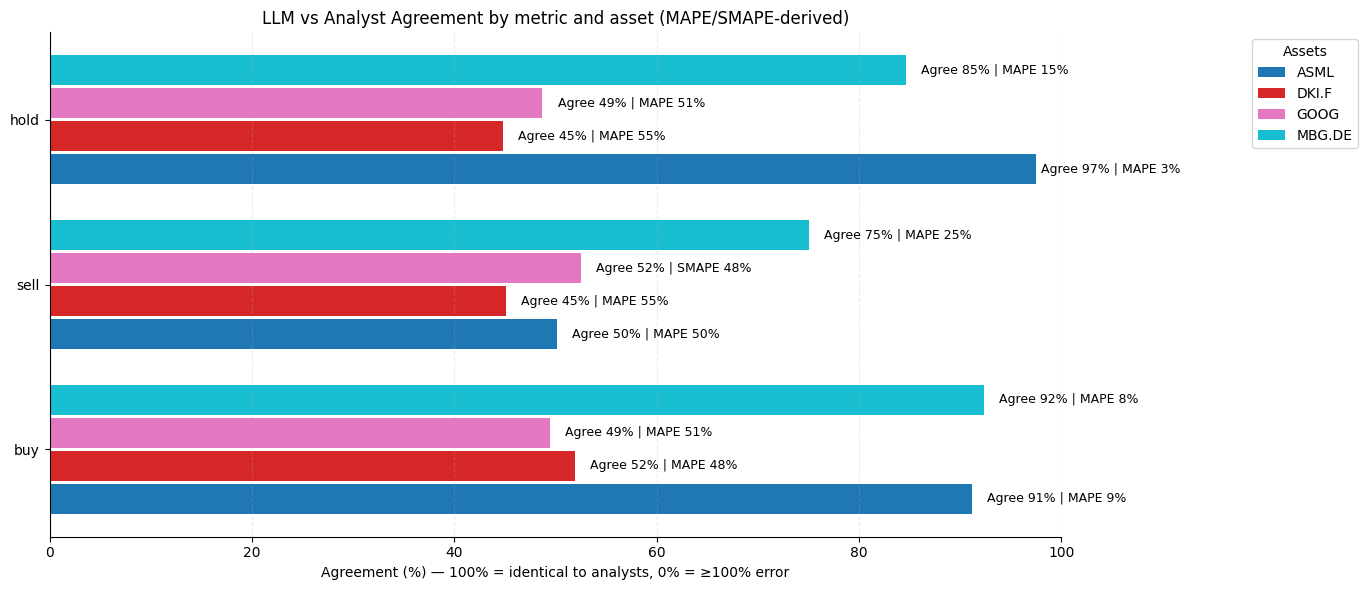

In [60]:
def plot_mape_agreement_grouped_horizontal_simple(
    comparison: dict,
    metrics: list[str] | None = None,
    annotate: bool = True,
):
    """
    Horizontal grouped bar chart showing ONLY the MAPE/SMAPE-derived agreement
    (no dashed lines, no MAD/Max annotations).

    Agreement is computed as:
        agreement_pct = 100 - min(100, error_pct)
    where error_pct is the MAPE (or SMAPE, if used when the analyst % is ~0).

    Parameters
    ----------
    comparison : dict
        Output of compare_llm_means_to_analysts_mape(...).
        Expected per asset:
            comparison[asset]["error"][metric] = {"metric": "MAPE"|"SMAPE", "value_pct": float}
    metrics : list[str] | None
        Metrics to display (default: ["buy","sell","hold"]).
    annotate : bool
        Whether to print labels like "Agree XX% | MAPE YY%".

    Returns
    -------
    (fig, ax) : matplotlib Figure and Axes
    """
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt

    if not isinstance(comparison, dict) or not comparison:
        raise ValueError("`comparison` must be a non-empty dict.")

    default_metrics = ["buy", "sell", "hold"]
    metrics_order = metrics or default_metrics
    metrics_order = [m for m in metrics_order if m in default_metrics]

    # Collect assets (skip summary)
    assets = [k for k in comparison.keys() if k != "_summary"]
    if not assets:
        raise ValueError("No asset entries found in `comparison`.")

    # Build tidy dataframe
    rows = []
    for asset in assets:
        err_block = (comparison.get(asset) or {}).get("error", {})
        for m in metrics_order:
            e = (err_block or {}).get(m, {})
            err_val = e.get("value_pct", None)
            kind = (e.get("metric") or "").strip().upper() if isinstance(e, dict) else ""
            if err_val is None:
                continue
            err_val = float(err_val)
            agree = max(0.0, 100.0 - min(100.0, err_val))
            rows.append({
                "metric": m,
                "asset": asset,
                "agreement_pct": agree,
                "error_pct": err_val,
                "error_metric": kind if kind in ("MAPE", "SMAPE") else "MAPE",
            })

    df = pd.DataFrame(rows)
    if df.empty:
        raise ValueError("No agreement values to plot (missing MAPE/SMAPE).")

    # Order metrics and sort
    df["metric"] = pd.Categorical(df["metric"], categories=metrics_order, ordered=True)
    df.sort_values(["metric", "asset"], inplace=True)

    # --- Plot (single axes, grouped horizontal) ---
    n_assets = len(assets)
    fig_width = max(14, 6 + 1.6 * n_assets)
    fig_height = max(6, 1.6 * len(metrics_order))
    fig, ax = plt.subplots(figsize=(fig_width, fig_height))

    y_centers = np.arange(len(metrics_order))
    cluster_height = 0.8
    bar_height = cluster_height / max(n_assets, 1)

    # Consistent colors per asset
    cmap = plt.cm.get_cmap("tab10", max(n_assets, 3))
    asset_colors = {asset: cmap(i % cmap.N) for i, asset in enumerate(assets)}

    for j, asset in enumerate(assets):
        sub = df[df["asset"] == asset]
        if sub.empty:
            continue

        offset = (j - (n_assets - 1) / 2) * bar_height
        y_pos = np.array([y_centers[metrics_order.index(m)] for m in sub["metric"]], dtype=float)
        vals  = sub["agreement_pct"].to_numpy(dtype=float)
        errs  = sub["error_pct"].to_numpy(dtype=float)
        kinds = sub["error_metric"].astype(str).to_list()

        bars = ax.barh(
            y=y_pos + offset,
            width=np.nan_to_num(vals, nan=0.0),
            height=bar_height * 0.9,
            label=asset,
            color=asset_colors[asset],
        )

        if annotate:
            for rect, a, e, k in zip(bars, vals, errs, kinds):
                lbl = f"Agree {a:.0f}% | {k} {e:.0f}%"
                ax.text(
                    min(a + 1.5, 98.0),
                    rect.get_y() + rect.get_height() / 2,
                    lbl,
                    va="center",
                    ha="left",
                    fontsize=9,
                )

    # Axes styling
    ax.set_xlim(0, 100)
    ax.set_xlabel("Agreement (%) — 100% = identical to analysts, 0% = ≥100% error")
    ax.set_yticks(y_centers)
    ax.set_yticklabels([m.replace("_", " ") for m in metrics_order])
    ax.set_title("LLM vs Analyst Agreement by metric and asset (MAPE/SMAPE-derived)")
    ax.grid(True, axis="x", linestyle="--", alpha=0.25)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # Legend (top-right)
    ax.legend(
        title="Assets",
        frameon=True,
        loc="upper right",
        bbox_to_anchor=(1.3, 1.0),
        ncols=1
    )

    fig.tight_layout()
    return fig, ax

# Example:
fig, ax = plot_mape_agreement_grouped_horizontal_simple(
    comparison=llm_vs_analyst_comparison,
    metrics=["buy","sell","hold"],
    annotate=True,
)
# plt.show()
